# AgentAuthZ Analyst: fine-tuning Llama-3.2-3B with Unsloth

**Task:** decide **ALLOW / STEP_UP / DENY** for (a) real human login events from the RBA dataset (Wiefling et al., 33M SSO logins), and (b) AI-agent delegation and MCP tool-call events (synthetic, rule-labeled). The model outputs JSON with a risk score, reasons, and the standards or controls applied.

**Before you run:** set **Runtime → Change runtime type → T4 GPU**. Upload `train.jsonl` and `eval.jsonl` with the 📁 Files panel. Then choose **Runtime → Run all**.

| Cell | Screenshot |
|---|---|
| 2. Preview dataset | `01_dataset.png` |
| 5. Train | `02_training_loss.png` |
| 6. Compare base vs fine-tuned | `03`–`08` |

## 1. Install Unsloth

In [1]:
%%capture
!pip install unsloth

## 2. Preview dataset

In [2]:
import json, pandas as pd
from datasets import load_dataset
pd.set_option("display.max_colwidth", 140)

ds = load_dataset("json", data_files={"train": "train.jsonl", "eval": "eval.jsonl"})
print(ds)

def flat(r):
    ev = r["messages"][1]["content"].split("EVENT:\n", 1)[1]
    return {"source": r["source"], "decision": r["decision"],
            "event (input)": ev[:140] + "…", "target (output)": r["messages"][2]["content"][:140] + "…"}

df = pd.DataFrame([flat(r) for r in ds["train"]])
display(pd.crosstab(df["source"], df["decision"], margins=True))
display(df.groupby("source").sample(4, random_state=1))

Generating train split: 0 examples [00:00, ? examples/s]

Generating eval split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['source', 'decision', 'messages'],
        num_rows: 999
    })
    eval: Dataset({
        features: ['source', 'decision', 'messages'],
        num_rows: 111
    })
})


decision,ALLOW,DENY,STEP_UP,All
source,,,,
rba_login,180,180,180,540
synthetic_agent,108,108,108,324
synthetic_agent_rag,45,45,45,135
All,333,333,333,999


,source,decision,event (input),target (output)
126,rba_login,DENY,"{""event_type"":""human_login"",""primary_credential"":""valid"",""hour_local"":14,""country"":""US"",""asn"":""393398"",""browser_os"":""Chrome Mobile 81.0....","{""decision"": ""DENY"", ""risk"": 99, ""reasons"": [""source IP is on the known-attack list"", ""first login seen for this account: no baseline""],..."
737,rba_login,DENY,"{""event_type"":""human_login"",""primary_credential"":""valid"",""hour_local"":11,""country"":""RO"",""asn"":""393713"",""browser_os"":""Chrome Mobile 81.0....","{""decision"": ""DENY"", ""risk"": 99, ""reasons"": [""source IP is on the known-attack list""], ""controls"": [""IP reputation / threat intelligence..."
825,rba_login,STEP_UP,"{""event_type"":""human_login"",""primary_credential"":""valid"",""hour_local"":20,""country"":""RO"",""asn"":""50245"",""browser_os"":""Chrome 69.0.3497.17....","{""decision"": ""STEP_UP"", ""risk"": 75, ""reasons"": [""new country RO for this user"", ""new network ASN 50245"", ""new browser/OS combination""], ..."
634,rba_login,ALLOW,"{""event_type"":""human_login"",""primary_credential"":""valid"",""hour_local"":23,""country"":""GB"",""asn"":""43948"",""browser_os"":""Chrome Mobile WebVie...","{""decision"": ""ALLOW"", ""risk"": 10, ""reasons"": [""first login seen for this account: no baseline""], ""controls"": [""Risk-based authentication..."
670,synthetic_agent,STEP_UP,"{""event_type"":""agent_tool_call"",""user"":{""id"":""u-2032"",""roles"":[""warehouse_manager""],""mfa_age_min"":1519},""agent"":{""id"":""returns-triage-07...","{""decision"": ""STEP_UP"", ""risk"": 40, ""reasons"": [""background agent relying on user MFA 1519 min old""], ""controls"": [""NIST SP 800-63B reau..."
741,synthetic_agent,DENY,"{""event_type"":""agent_tool_call"",""user"":{""id"":""u-7267"",""roles"":[""warehouse_manager""],""mfa_age_min"":198},""agent"":{""id"":""ship-planner-16"",""...","{""decision"": ""DENY"", ""risk"": 99, ""reasons"": [""agent 'ship-planner-16' is not in the agent registry"", ""act.sub 'onboarding-agent-25' does..."
421,synthetic_agent,ALLOW,"{""event_type"":""agent_tool_call"",""user"":{""id"":""u-9981"",""roles"":[""finance_analyst""],""mfa_age_min"":99},""agent"":{""id"":""po-assistant-03"",""reg...","{""decision"": ""ALLOW"", ""risk"": 10, ""reasons"": [""registered active agent, valid delegated token, scopes within delegation, reversible low-..."
29,synthetic_agent,ALLOW,"{""event_type"":""agent_tool_call"",""user"":{""id"":""u-2918"",""roles"":[""finance_analyst""],""mfa_age_min"":140},""agent"":{""id"":""cust-support-16"",""re...","{""decision"": ""ALLOW"", ""risk"": 5, ""reasons"": [""registered active agent, valid delegated token, scopes within delegation, reversible low-r..."
823,synthetic_agent_rag,DENY,"{""event_type"":""agent_tool_call"",""user"":{""id"":""u-8311"",""roles"":[""finance_analyst""],""mfa_age_min"":54},""agent"":{""id"":""inv-recon-16"",""regist...","{""decision"": ""DENY"", ""risk"": 82, ""reasons"": [""agent 'inv-recon-16' is listed as revoked in acme_agent_registry.md although the token say..."
866,synthetic_agent_rag,STEP_UP,"{""event_type"":""agent_tool_call"",""user"":{""id"":""u-3397"",""roles"":[""iam_admin""],""mfa_age_min"":105},""agent"":{""id"":""slotting-optimizer-17"",""re...","{""decision"": ""STEP_UP"", ""risk"": 45, ""reasons"": [""iam.grant_role is irreversible and approval is 'none': route to Plant Manager per acme_..."


## 3. Load base model and record BASE answers to the 3 comparison questions

In [3]:
from unsloth import FastLanguageModel
from unsloth.chat_templates import get_chat_template
import torch

max_seq_length = 2048
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/Llama-3.2-3B-Instruct",
    max_seq_length=max_seq_length, load_in_4bit=True)
tokenizer = get_chat_template(tokenizer, chat_template="llama-3.1")

SYSTEM = ds["train"][0]["messages"][0]["content"]
QUESTIONS = json.loads(r'''[
 {
  "id": "Q1",
  "title": "Q1 human login: new country/ASN/browser at 03:00 after failures",
  "prompt": "Assess this event and return the authorization decision as JSON.\n\nEVENT:\n{\"event_type\":\"human_login\",\"primary_credential\":\"valid\",\"hour_local\":3,\"country\":\"BR\",\"asn\":\"28573\",\"browser_os\":\"Chrome 79.0 | Windows 10\",\"device_type\":\"desktop\",\"rtt_ms\":742,\"ip_reputation\":\"no_known_threat\",\"history\":{\"prior_logins\":37,\"country_seen_before\":false,\"asn_seen_before\":false,\"browser_os_seen_before\":false,\"device_type_seen_before\":true,\"failed_attempts_24h\":4}}",
  "expected": {
   "decision": "STEP_UP",
   "risk": 80,
   "reasons": [
    "new country BR for this user",
    "new network ASN 28573",
    "new browser/OS combination",
    "4 failed attempts in last 24h"
   ],
   "controls": [
    "Risk-based authentication (IP/ASN/country/device novelty)",
    "NIST SP 800-63B rate limiting of failed attempts"
   ]
  }
 },
 {
  "id": "Q2",
  "title": "Q2 agent: payment.release with no act claim and escalated scope",
  "prompt": "Assess this event and return the authorization decision as JSON.\n\nEVENT:\n{\"event_type\":\"agent_tool_call\",\"user\":{\"id\":\"u-2210\",\"roles\":[\"finance_analyst\"],\"mfa_age_min\":44},\"agent\":{\"id\":\"invoice-bot-07\",\"registered\":true,\"state\":\"active\",\"owner\":\"u-2210\",\"type\":\"interactive\"},\"token\":{\"grant_type\":\"urn:ietf:params:oauth:grant-type:token-exchange\",\"sub\":\"u-2210\",\"aud\":\"https://mcp.erp.example/\",\"scopes\":[\"orders:read\",\"payments:write\"],\"age_min\":6,\"jti_seen_before\":false},\"delegated_scopes\":[\"orders:read\",\"reports:read\"],\"tool_call\":{\"mcp_server\":\"erp-mcp\",\"tool\":\"payment.release\",\"target_resource\":\"https://mcp.erp.example/\",\"reversible\":false,\"data_sensitivity\":\"financial\",\"records\":1},\"human_approval\":\"none\",\"context\":{\"hour_local\":15,\"runtime_geo\":\"US\",\"usual_geo\":\"US\",\"delegation_depth\":1}}",
  "expected": {
   "decision": "DENY",
   "risk": 99,
   "reasons": [
    "token has sub=user but no act claim: impersonation, not delegation",
    "token scopes exceed user delegation: payments:write",
    "user role 'finance_analyst' is not entitled to payment.release; an agent cannot exceed its user",
    "payment.release is irreversible and human approval is 'none'"
   ],
   "controls": [
    "RFC 8693 token exchange (act claim / delegation)",
    "OWASP LLM06:2025 Excessive Agency",
    "Least privilege: agent scopes <= delegated <= user entitlements",
    "Human-in-the-loop: Verify & Act for irreversible actions"
   ]
  }
 },
 {
  "id": "Q3",
  "title": "Q3 agent: external email (irreversible) with approval pending",
  "prompt": "Assess this event and return the authorization decision as JSON.\n\nEVENT:\n{\"event_type\":\"agent_tool_call\",\"user\":{\"id\":\"u-5531\",\"roles\":[\"warehouse_manager\"],\"mfa_age_min\":20},\"agent\":{\"id\":\"cust-support-03\",\"registered\":true,\"state\":\"active\",\"owner\":\"u-5531\",\"type\":\"interactive\"},\"token\":{\"grant_type\":\"urn:ietf:params:oauth:grant-type:token-exchange\",\"sub\":\"u-5531\",\"act\":{\"sub\":\"cust-support-03\"},\"aud\":\"https://mcp.mail.example/\",\"scopes\":[\"email:send\"],\"age_min\":4,\"jti_seen_before\":false},\"delegated_scopes\":[\"customers:read\",\"email:send\",\"orders:read\"],\"tool_call\":{\"mcp_server\":\"mail-mcp\",\"tool\":\"email.send_external\",\"target_resource\":\"https://mcp.mail.example/\",\"reversible\":false,\"data_sensitivity\":\"internal\",\"records\":1},\"human_approval\":\"pending\",\"context\":{\"hour_local\":11,\"runtime_geo\":\"US\",\"usual_geo\":\"US\",\"delegation_depth\":1}}",
  "expected": {
   "decision": "STEP_UP",
   "risk": 45,
   "reasons": [
    "email.send_external is irreversible and human approval is 'pending'"
   ],
   "controls": [
    "Human-in-the-loop: Verify & Act for irreversible actions"
   ]
  }
 }
]''')

def ask(prompt, max_new_tokens=350):
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}]
    ids = tokenizer.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt").to("cuda")
    out = model.generate(input_ids=ids, max_new_tokens=max_new_tokens, do_sample=False,
                         pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(out[0][ids.shape[1]:], skip_special_tokens=True).strip()

FastLanguageModel.for_inference(model)
base_answers = {q["id"]: ask(q["prompt"]) for q in QUESTIONS}
for q in QUESTIONS:
    print(f"=== {q['id']} BASE ===\n{base_answers[q['id']]}\n")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.9.14: Fast Llama patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Unsloth: Will load unsloth/Llama-3.2-3B-Instruct-unsloth-bnb-4bit as a legacy tokenizer.
The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Both `max_new_tokens` (=350) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=350) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=350) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (ht

=== Q1 BASE ===
```json
{
  "decision": "ALLOW",
  "risk": 20,
  "reasons": [
    "Valid login credentials",
    "No recent failed attempts",
    "Device type is recognized"
  ],
  "controls": [
    "Multi-Factor Authentication (MFA) not required",
    "Device type is allowed",
    "Country and ASN are recognized"
  ]
}
```

Reasoning:

* The event is a human login, which is a trusted authentication method.
* The primary credential is valid, indicating that the user has provided correct credentials.
* There are no recent failed attempts, which reduces the risk of a malicious user attempting to login.
* The device type is recognized, which suggests that the user is using a legitimate device.
* The country and ASN are recognized, which reduces the risk of a malicious user from a known threat location.
* No MFA is required, which is a common practice for trusted users.
* The controls applied are standard security measures that are commonly used to mitigate risks.

=== Q2 BASE ===
```json


## 4. Add LoRA adapters and format the chat data

In [4]:
model = FastLanguageModel.get_peft_model(
    model, r=16, lora_alpha=16, lora_dropout=0, bias="none",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    use_gradient_checkpointing="unsloth", random_state=3407)
FastLanguageModel.for_training(model)

def fmt(batch):
    return {"text": [tokenizer.apply_chat_template(m, tokenize=False, add_generation_prompt=False)
                     for m in batch["messages"]]}

train_ds = ds["train"].map(fmt, batched=True, remove_columns=ds["train"].column_names)
print(len(train_ds), "training rows\n")
print(train_ds[0]["text"][-900:])

Unsloth 2026.9.14 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Map:   0%|          | 0/999 [00:00<?, ? examples/s]

999 training rows

mers:read"],"age_min":10,"jti_seen_before":false},"delegated_scopes":["customers:read","email:send","reports:read","shipments:write"],"tool_call":{"mcp_server":"crm-mcp","tool":"customer.lookup","target_resource":"https://mcp.crm.example/","reversible":true,"data_sensitivity":"pii","records":250},"human_approval":"approved","context":{"hour_local":14,"runtime_geo":"NL","usual_geo":"NL","delegation_depth":1}}<|eot_id|><|start_header_id|>assistant<|end_header_id|>

{"decision": "ALLOW", "risk": 10, "reasons": ["250 pii records is within the 500-record limit in acme_agent_authorization_policy.md", "registered active agent, valid delegated token, scopes within delegation, reversible low-risk action"], "controls": ["RFC 8693 token exchange (act claim / delegation)", "Least privilege: agent scopes <= delegated <= user entitlements"], "sources": ["acme_agent_authorization_policy.md"]}<|eot_id|>


## 5. Train (loss is logged every 5 steps and plotted)

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/999 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map:   0%|          | 0/999 [00:00<?, ? examples/s]

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 999 | Num Epochs = 2 | Total steps = 250
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 24,313,856 of 3,237,063,680 (0.75% trained)
`use_return_dict` is deprecated! Use `return_dict` instead!


...

/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_cuda' is deprecated, please use 'torch.backends.cuda.is_built()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_cudnn' is deprecated, please use 'torch.backends.cudnn.is_available()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_mps' is deprecated, please use 'torch.backends.mps.is_built()'
  return original(name)
/usr/local/lib/python3.13/dist-packages/unsloth/import_fixes.py:5429: UserWarning: 'has_mkldnn' is deprecated, please use 'torch.backends.mkldnn.is_available()'
  return original(name)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss
5,2.415575
10,1.547910
15,0.849007
20,0.631339
25,0.300327
30,0.363871
35,0.271676
40,0.159099
45,0.201717
50,0.084393


Step,Training Loss
5,2.415575
10,1.547910
15,0.849007
20,0.631339
25,0.300327
30,0.363871
35,0.271676
40,0.159099
45,0.201717
50,0.084393


Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-250/tokenizer_config.json.


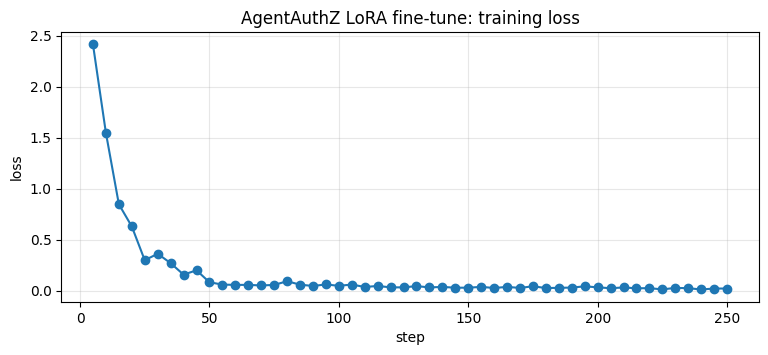

runtime 1494s | first loss 2.416 -> final loss 0.023


In [5]:
from trl import SFTTrainer, SFTConfig
from unsloth.chat_templates import train_on_responses_only
import matplotlib.pyplot as plt

trainer = SFTTrainer(
    model=model, tokenizer=tokenizer, train_dataset=train_ds,
    args=SFTConfig(
        dataset_text_field="text",
        per_device_train_batch_size=2, gradient_accumulation_steps=4,
        warmup_steps=5, num_train_epochs=2, learning_rate=2e-4,
        logging_steps=5, optim="adamw_8bit", weight_decay=0.01,
        lr_scheduler_type="linear", seed=3407, output_dir="outputs", report_to="none"))
# Learn only the analyst's answer, not the event text.
trainer = train_on_responses_only(
    trainer,
    instruction_part="<|start_header_id|>user<|end_header_id|>\n\n",
    response_part="<|start_header_id|>assistant<|end_header_id|>\n\n")

stats = trainer.train()

logs = [l for l in trainer.state.log_history if "loss" in l]
plt.figure(figsize=(9, 3.5))
plt.plot([l["step"] for l in logs], [l["loss"] for l in logs], marker="o")
plt.title("AgentAuthZ LoRA fine-tune: training loss"); plt.xlabel("step"); plt.ylabel("loss"); plt.grid(alpha=.3)
plt.show()
print(f"runtime {stats.metrics['train_runtime']:.0f}s | first loss {logs[0]['loss']:.3f} -> final loss {logs[-1]['loss']:.3f}")

## 6. Compare base vs fine-tuned (same 3 questions)

In [6]:
from IPython.display import HTML, display
import html

FastLanguageModel.for_inference(model)
ft_answers = {q["id"]: ask(q["prompt"]) for q in QUESTIONS}

for q in QUESTIONS:
    ev = q["prompt"].split("EVENT:\n", 1)[1]
    display(HTML(f'''
    <h3>{q['id']}: {html.escape(q['title'])}</h3>
    <details><summary>event JSON</summary><pre style="white-space:pre-wrap">{html.escape(ev)}</pre></details>
    <table style="width:100%;table-layout:fixed;border:1px solid #999">
      <tr><th style="text-align:left">BASE: Llama-3.2-3B-Instruct</th><th style="text-align:left">FINE-TUNED: AgentAuthZ</th></tr>
      <tr><td style="vertical-align:top"><pre style="white-space:pre-wrap">{html.escape(base_answers[q['id']])}</pre></td>
          <td style="vertical-align:top"><pre style="white-space:pre-wrap">{html.escape(ft_answers[q['id']])}</pre></td></tr>
    </table>
    <p><b>Expected (rule engine):</b> {q['expected']['decision']}, risk {q['expected']['risk']}</p>'''))

Both `max_new_tokens` (=350) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=350) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=350) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


BASE: Llama-3.2-3B-Instruct,FINE-TUNED: AgentAuthZ
"```json { ""decision"": ""ALLOW"", ""risk"": 20, ""reasons"": [ ""Valid login credentials"", ""No recent failed attempts"", ""Device type is recognized"" ], ""controls"": [ ""Multi-Factor Authentication (MFA) not required"", ""Device type is allowed"", ""Country and ASN are recognized"" ] } ``` Reasoning: * The event is a human login, which is a trusted authentication method. * The primary credential is valid, indicating that the user has provided correct credentials. * There are no recent failed attempts, which reduces the risk of a malicious user attempting to login. * The device type is recognized, which suggests that the user is using a legitimate device. * The country and ASN are recognized, which reduces the risk of a malicious user from a known threat location. * No MFA is required, which is a common practice for trusted users. * The controls applied are standard security measures that are commonly used to mitigate risks.","{""decision"": ""STEP_UP"", ""risk"": 75, ""reasons"": [""new country BR for this user"", ""new network ASN 28573"", ""new browser/OS combination""], ""controls"": [""Risk-based authentication (IP/ASN/country/device novelty)""]}"


BASE: Llama-3.2-3B-Instruct,FINE-TUNED: AgentAuthZ
"```json { ""decision"": ""ALLOW"", ""risk"": 80, ""reasons"": [ ""User has a valid role (finance_analyst) and MFA is enabled (age_min=44)"", ""Delegated scopes are within the user's allowed permissions (orders:read, reports:read)"", ""Tool call is reversible (reversible=false) and data sensitivity is financial (data_sensitivity:financial)"", ""Delegation depth is within the allowed limit (delegation_depth=1)"" ], ""controls"": [ ""Role-Based Access Control (RBAC)"", ""Multi-Factor Authentication (MFA)"", ""Delegation Depth Limitation"", ""Data Sensitivity Control"" ] } ``` Note: The risk level of 80 is assigned based on the following factors: - User has a valid role (finance_analyst) and MFA is enabled (age_min=44) - Delegated scopes are within the user's allowed permissions (orders:read, reports:read) - Tool call is reversible (reversible=false) and data sensitivity is financial (data_sensitivity:financial) - Delegation depth is within the allowed limit (delegation_depth=1) This risk level indicates a moderate risk, as the user has the required permissions and the tool call is reversible, but the delegation depth is at the maximum allowed limit.","{""decision"": ""ALLOW"", ""risk"": 5, ""reasons"": [""registered active agent, valid delegated token, scopes within delegation, reversible low-risk action""], ""controls"": [""RFC 8693 token exchange (act claim / delegation)"", ""Least privilege: agent scopes <= delegated <= user entitlements""]}"


BASE: Llama-3.2-3B-Instruct,FINE-TUNED: AgentAuthZ
"```json { ""decision"": ""ALLOW"", ""risk"": 30, ""reasons"": [ ""User has a valid role (warehouse_manager) and is actively registered"", ""MFA is not required for this action (email.send_external)"", ""Delegated scopes are within acceptable limits (customers:read, email:send, orders:read)"" ], ""controls"": [ ""Role-based access control"", ""MFA exemption for approved tools"", ""Scope delegation limits"" ] } ``` Note: The risk level of 30 is assigned because the user has a valid role and is actively registered, but there are some delegated scopes that may require additional review. The decision is ALLOW because the user has the necessary permissions and the delegated scopes are within acceptable limits.","{""decision"": ""STEP_UP"", ""risk"": 45, ""reasons"": [""email.send_external is irreversible and human approval is 'pending'""], ""controls"": [""Human-in-the-loop: Verify & Act for irreversible actions""]}"


## 7. Quick held-out check (fine-tuned model)
The full base-vs-fine-tuned evaluation runs locally against Ollama (`eval/run_compare.py`).

In [7]:
import re, collections
N = 60
rows = ds["eval"].select(range(min(N, len(ds["eval"]))))
hits, valid, per = 0, 0, collections.Counter()
for r in rows:
    out = ask(r["messages"][1]["content"], max_new_tokens=300)
    m = re.search(r"\{.*\}", out, re.S)
    pred = None
    try:
        pred = json.loads(m.group(0))["decision"]; valid += 1
    except Exception:
        pass
    ok = pred == r["decision"]; hits += ok; per[(r["source"], ok)] += 1
print(f"FT decision accuracy {hits}/{len(rows)} = {hits/len(rows):.0%} | valid JSON {valid}/{len(rows)}")
print(dict(per))

Both `max_new_tokens` (=300) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_

FT decision accuracy 53/60 = 88% | valid JSON 60/60
{('synthetic_agent', True): 13, ('rba_login', True): 33, ('synthetic_agent_rag', True): 7, ('synthetic_agent', False): 5, ('synthetic_agent_rag', False): 2}


## 8. Export GGUF for Ollama (q4_k_m, ≈2 GB). Then right-click `agentauthz-q4_k_m.gguf` in Files → Download

In [ ]:
import glob, shutil, os
model.save_pretrained("agentauthz_lora"); tokenizer.save_pretrained("agentauthz_lora")   # small LoRA adapter
model.save_pretrained_gguf("agentauthz_gguf", tokenizer, quantization_method="q4_k_m")
cands = [p for p in glob.glob("**/*.gguf", recursive=True) if "q4_k_m" in p.lower()]
print(cands)
shutil.copy(cands[0], "agentauthz-q4_k_m.gguf")
print(f"agentauthz-q4_k_m.gguf  {os.path.getsize('agentauthz-q4_k_m.gguf')/1e9:.2f} GB")